In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

In [6]:
path = '/home/kale-chen/Documents/PET/calibration_files'
names = ['2022Apr', '2024Nov', '2025Oct', '2026Aug']
darkpaths = [f'{path}/{name}/disc_calibration_dark.tsv' for name in names]
basepaths = [f'{path}/{name}/disc_calibration_baseline.tsv' for name in names]

 50%|█████     | 2/4 [00:04<00:04,  2.25s/it]


KeyboardInterrupt: 

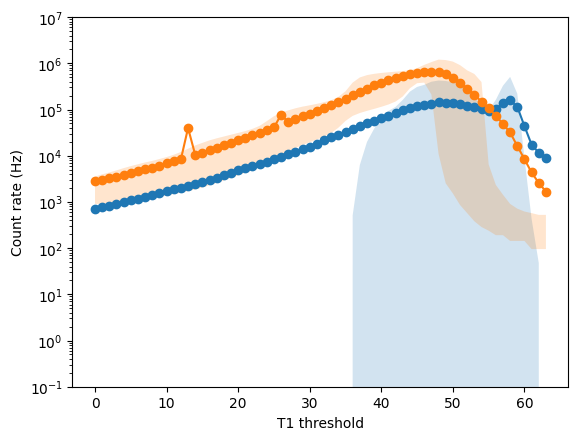

In [7]:
for getn in tqdm(range(len(darkpaths))):
    colsdark = ["port", "slave", "chip", "channel", "disc", "threshold", "rate"]
    dark = pd.read_csv(darkpaths[getn], sep="\t", header=None, names=colsdark)
    colsbase = ["port", "slave", "chip", "channel", "disc", "rate"]
    base = pd.read_csv(basepaths[getn], sep="\t", header=None, names=colsbase)
    thresholds = []
    medians = []
    q16s = []
    q84s = []
    rel = dark[dark['disc'] == 'vth_t1']

    for i in range(64):
        reli = rel[rel['threshold'] == i]['rate']

        thresholds.append(i)
        medians.append(np.mean(reli))
        q16s.append(np.percentile(reli, 16))
        q84s.append(np.percentile(reli, 84))

    plt.plot(thresholds, medians, 'o-')

    plt.fill_between(thresholds,q16s,q84s,alpha=0.2)

    plt.yscale('log')
    plt.ylim(1e-1, 1e7)
    plt.xlabel('T1 threshold')
    plt.ylabel('Count rate (Hz)')
plt.show()

In [56]:
print(base)

      port  slave  chip  channel  disc  rate
0        0      0     0        0    44     3
1        0      0     1        0    49     7
2        0      0     2        0    50     6
3        0      0     3        0    48     5
4        0      0     4        0    49     6
...    ...    ...   ...      ...   ...   ...
6139     1      2    11       63    51     6
6140     1      2    12       63    45     7
6141     1      2    13       63    53     7
6142     1      2    14       63    48     4
6143     1      2    15       63    49     6

[6144 rows x 6 columns]


In [37]:
print(df[df['disc'] == 'vth_t1'])

         port  slave  chip  channel    disc  threshold          rate
0           2      0     2        0  vth_t1          0  10824.203491
1           2      0     3        0  vth_t1          0   1430.511475
2           2      0     4        0  vth_t1          0   7486.343384
3           2      0     5        0  vth_t1          0   2145.767212
4           2      0     8        0  vth_t1          0   2670.288086
...       ...    ...   ...      ...     ...        ...           ...
1474555     2      5    11       63  vth_t1         63      0.000000
1474556     2      5    12       63  vth_t1         63      0.000000
1474557     2      5    13       63  vth_t1         63      0.000000
1474558     2      5    14       63  vth_t1         63      0.000000
1474559     2      5    15       63  vth_t1         63      0.000000

[1474560 rows x 7 columns]


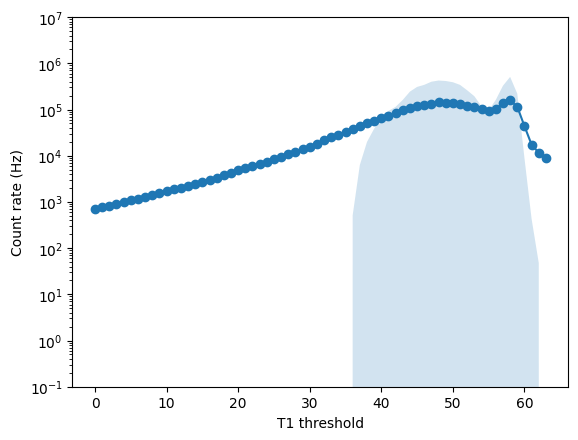

In [49]:
thresholds = []
medians = []
q16s = []
q84s = []
rel = df[df['disc'] == 'vth_t1']

for i in range(64):
    reli = rel[rel['threshold'] == i]['rate']

    thresholds.append(i)
    medians.append(np.mean(reli))
    q16s.append(np.percentile(reli, 16))
    q84s.append(np.percentile(reli, 84))

plt.plot(thresholds, medians, 'o-')

plt.fill_between(thresholds,q16s,q84s,alpha=0.2)

plt.yscale('log')
plt.ylim(1e-1, 1e7)
plt.xlabel('T1 threshold')
plt.ylabel('Count rate (Hz)')
plt.show()

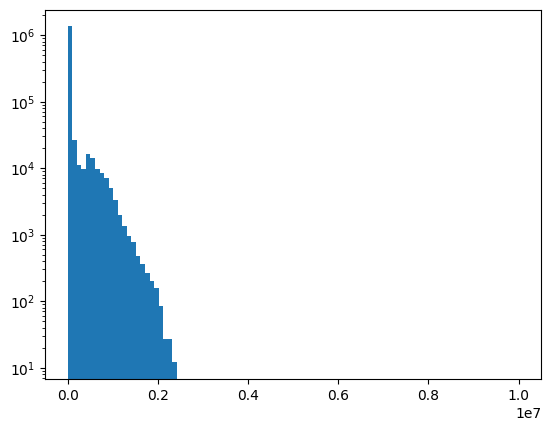

In [41]:
plt.hist(df[df['disc'] == 'vth_t1']['rate'], bins = np.linspace(0, 1e7, 100))
plt.yscale('log')
plt.show()